# Potomac River at Little Falls — USGS-01646500

This gauge watches the Potomac River at Little Falls, right where the river leaves Maryland and enters Washington, DC. Since March 1930, the USGS has measured how much water flows past this spot every single day. Everything that happens in the 11,560 square miles of land that drains into the river ends up in this one number.

It is one of the most watched gauges in the country, for a simple reason: **the water that passes Little Falls is the water the capital region drinks.**

Important facts:
* **Drinking water.** DC and the surrounding suburbs take about three-quarters of their water from the Potomac. The pumping station next to the gauge is part of the Washington Aqueduct. Below the gauge the river is "managed", because pipes pull water out of it, so Little Falls is the last honest look at how much water the basin actually produced.
* **Drought.** When the number here gets too low, the region starts releasing water from backup reservoirs and asks people to water their lawns less. The 2022 drought showed this: flows fell to near-record lows and restrictions followed.
* **Floods.** The same gauge is the early warning for big storms and ice jams. The huge flood of March 1936 (about as big as the 1889 one, which happened before the daily record begins) came through right here.

## Install and imports

In [ ]:
%pip install dataretrieval # USGS package for data retrieval
%pip install geopandas
%pip install statsmodels
%pip install --index-url https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ rhis-ts==0.1.0

In [1]:
from rhis_ts import Rhis
from statsmodels.tsa.seasonal import seasonal_decompose
from dataretrieval import waterdata # https://waterdata.usgs.gov/?utm_source=chatgpt.com
from helpers import build_rhis_evol_df, build_repr_df
from plotting import plot_rhis_evolution # Helper function to plot the representative series along with their p-value evolutions

## Getting the data

The daily discharge record runs from March 1930 to today. Let's pull it and take a first look at how this river behaves.

In [2]:
# Get daily streamflow data (returns DataFrame and metadata)
df, metadata = waterdata.get_daily(
    monitoring_location_id="USGS-01646500",
    parameter_code="00060",  # Discharge
    time="1930-01-01/2026-10-28",
)

df.info()

Retrieving: daily · 1 page · 35,306 rows


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 35306 entries, 0 to 35305
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype              
---  ------                  --------------  -----              
 0   geometry                35306 non-null  geometry           
 1   time_series_id          35306 non-null  str                
 2   monitoring_location_id  35306 non-null  str                
 3   parameter_code          35306 non-null  str                
 4   statistic_id            35306 non-null  str                
 5   time                    35306 non-null  datetime64[us]     
 6   value                   35306 non-null  float64            
 7   unit_of_measure         35306 non-null  str                
 8   approval_status         35306 non-null  str                
 9   qualifier               345 non-null    object             
 10  last_modified           35306 non-null  datetime64[us, UTC]
 11  daily_id                35306 non

In [3]:
df = df.set_index('time') # Set time as the dataframe index, so Rhis doesn't treat it as data to be analyzed
target_df = df[['value']].rename(columns={'value': 'flow'}).copy()
target_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35306 entries, 1930-03-01 to 2026-10-28
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   flow    35306 non-null  float64
dtypes: float64(1)
memory usage: 551.7 KB


## Exploratory analysis

Before running any statistical test, it pays to *look* at the data. This section answers five practical questions:

1. **Is the record complete?** Gaps and provisional values change what the tests "see".
2. **What does a typical flow look like?** The shape of the distribution explains why RHIS-TS uses non-parametric tests.
3. **Is there a seasonal cycle?** Seasons are the most common reason a streamflow series fails the randomness test.
4. **Does today's flow "remember" yesterday's?** This memory (persistence) is what the independence test detects.
5. **Are there long-term changes?** Shifts and trends are what the homogeneity and stationarity tests detect.

No knowledge of statistics is needed to follow along: every plot comes with a short "how to read it".

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Colors used in this section (one color per role, kept consistent across plots)
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
MUTED, GRID = '#52514e', '#e6e5e1'

flow = target_df['flow']  # daily mean discharge, ft³/s


def tidy(ax):
    """Light grid, no top/right frame: keeps the eye on the data."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(MUTED)

### 0. A first look at the series

Before answering any question, let's simply plot the data. The top panel shows the whole daily record, almost a century of it. The bottom panel zooms in on the last three years, where you can see how the flow changes from day to day.

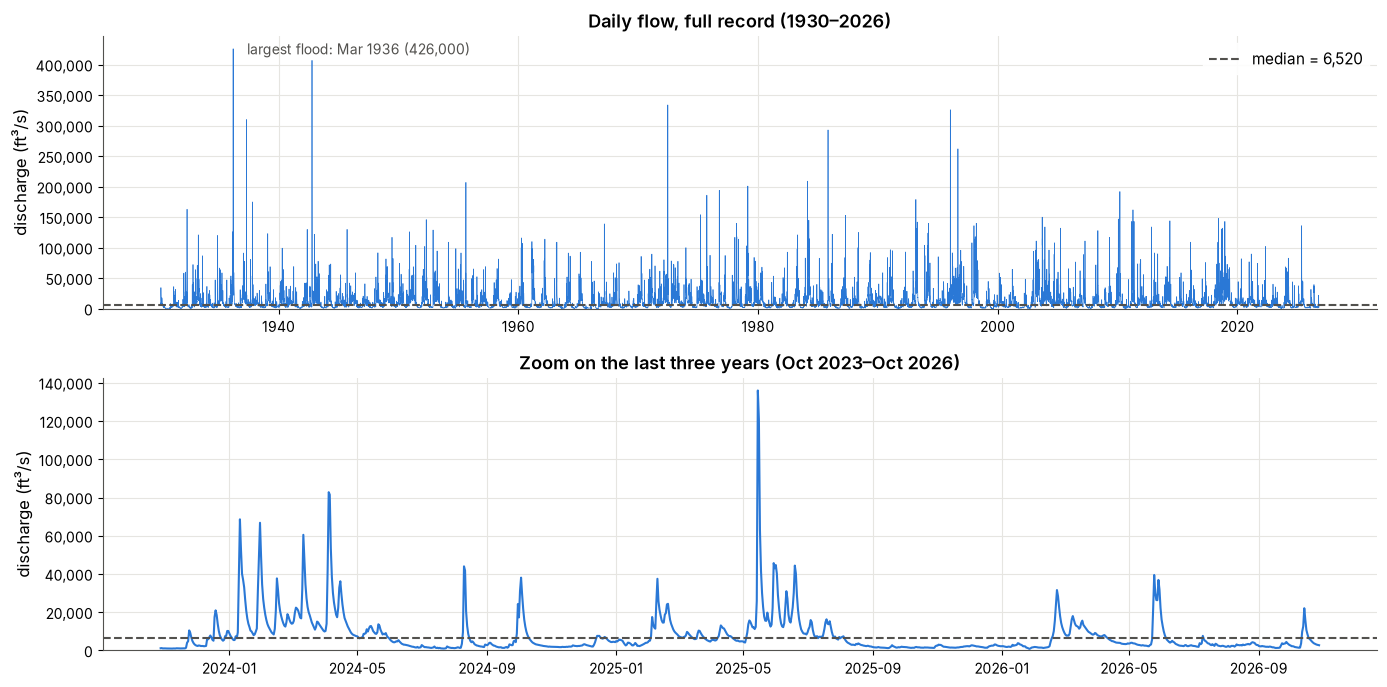

In [5]:
from matplotlib.ticker import StrMethodFormatter

recent = flow.loc[flow.index.max() - pd.DateOffset(years=3):]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))

# Top: the full daily record, 1930 to today
axes[0].plot(flow.index, flow, color=BLUE, linewidth=0.5)
axes[0].axhline(flow.median(), color=MUTED, linestyle='--', linewidth=1.5, label=f'median = {flow.median():,.0f}')
axes[0].annotate(f'largest flood: {flow.idxmax():%b %Y} ({flow.max():,.0f})', (flow.idxmax(), flow.max()),
                 textcoords='offset points', xytext=(10, -4), color=MUTED, fontsize=10)
axes[0].set_title(f'Daily flow, full record ({flow.index.min():%Y}–{flow.index.max():%Y})')
axes[0].legend(loc='upper right')

# Bottom: the last three years, where the day-to-day texture is visible
axes[1].plot(recent.index, recent, color=BLUE, linewidth=1.5)
axes[1].axhline(flow.median(), color=MUTED, linestyle='--', linewidth=1.5)
axes[1].set_title(f'Zoom on the last three years ({recent.index.min():%b %Y}–{recent.index.max():%b %Y})')

for ax in axes:
    ax.set_ylabel('discharge (ft³/s)')
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    tidy(ax)

plt.tight_layout()
plt.show()

**How to read it:** in the full record (top), the series looks like a dense band near the bottom with sharp spikes rising out of it. Each spike is a flood, and the March 1936 flood dwarfs everything else. Most days sit far below the spikes, near the dashed median line. The zoom (bottom) shows what that dense band really is: flows rise in winter and spring, fall to a low in late summer and fall, and change smoothly from one day to the next rather than jumping around at random.

These first impressions (a few huge floods, a yearly rhythm, smooth day-to-day changes) are exactly what the five questions below look at more closely.

### 1. Is the record complete?

Statistical tests read the values **in order** and do not know the dates. A missing day is simply skipped, so the test sees two days that were not really consecutive. Let's check how many days are missing and how many values are still *provisional* (recent data that USGS may still revise).

In [6]:
expected_days = pd.date_range(flow.index.min(), flow.index.max(), freq='D')
missing_days = expected_days.difference(flow.index)

print(f"First day:      {flow.index.min():%Y-%m-%d}")
print(f"Last day:       {flow.index.max():%Y-%m-%d}")
print(f"Days with data: {len(flow):,} of {len(expected_days):,} expected")
print(f"Missing days:   {len(missing_days):,} ({len(missing_days) / len(expected_days):.2%})")
print(f"Zero or negative flows: {(flow <= 0).sum()}")
print()
print("Approval status of the values:")
print(df['approval_status'].value_counts().to_string())

First day:      1930-03-01
Last day:       2026-10-28
Days with data: 35,306 of 35,306 expected
Missing days:   0 (0.00%)
Zero or negative flows: 0

Approval status of the values:
approval_status
Approved       35101
Provisional      205


**How to read it:** there are no missing days and no zero or negative flows, so gaps will not distort the tests. Provisional values cover only the most recent months; they are fine for exploration, but keep in mind that the **last few months may change** when USGS approves them — and RHIS-TS gives special weight to the most recent data.

Also note that the first and last years are **incomplete** (the record starts in March 1930 and ends in October 2026). An annual average computed from a partial year misses part of the seasonal cycle, so those two years are not comparable with the others.

### 2. What does a typical flow look like?

In [7]:
print(flow.describe(percentiles=[0.1, 0.5, 0.9]).round(0).to_string())
print()
print(f"Lowest daily flow:  {flow.min():,.0f} ft³/s on {flow.idxmin():%Y-%m-%d}")
print(f"Highest daily flow: {flow.max():,.0f} ft³/s on {flow.idxmax():%Y-%m-%d}")
print(f"The mean is {flow.mean() / flow.median():.1f}x the median")

count     35306.0
mean      11329.0
std       15832.0
min         121.0
10%        1700.0
50%        6520.0
90%       25300.0
max      426000.0

Lowest daily flow:  121 ft³/s on 1966-09-09
Highest daily flow: 426,000 ft³/s on 1936-03-19
The mean is 1.7x the median


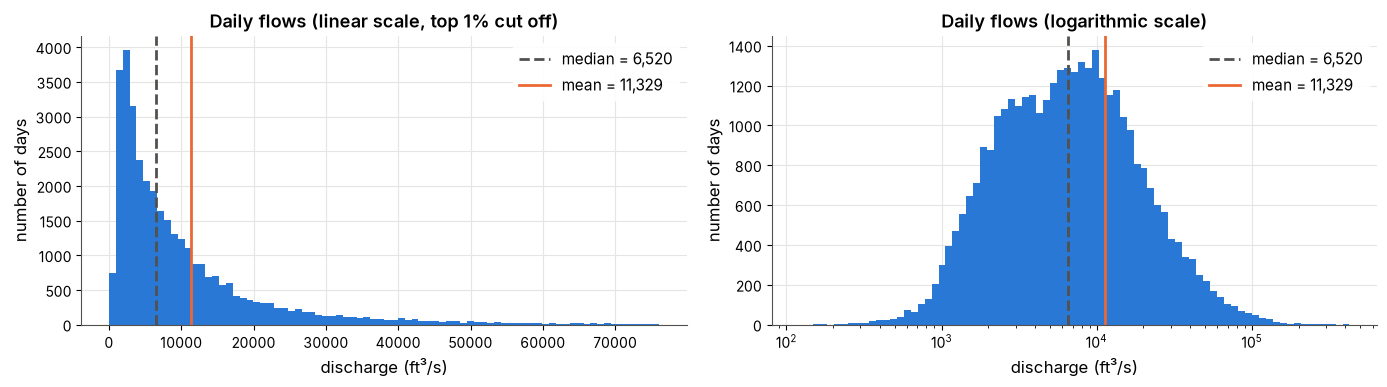

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(flow, bins=80, range=(0, flow.quantile(0.99)), color=BLUE)
axes[0].set_title('Daily flows (linear scale, top 1% cut off)')

axes[1].hist(flow, bins=np.logspace(np.log10(flow[flow > 0].min()), np.log10(flow.max()), 80), color=BLUE)
axes[1].set_xscale('log')
axes[1].set_title('Daily flows (logarithmic scale)')

for ax in axes:
    ax.axvline(flow.median(), color=MUTED, linestyle='--', linewidth=2, label=f'median = {flow.median():,.0f}')
    ax.axvline(flow.mean(), color=ORANGE, linewidth=2, label=f'mean = {flow.mean():,.0f}')
    ax.set_xlabel('discharge (ft³/s)')
    ax.set_ylabel('number of days')
    ax.legend()
    tidy(ax)

plt.tight_layout()
plt.show()

**How to read it:** most days have modest flows, while a few flood days are many times larger, so the distribution has a long tail to the right (it is *skewed*). The floods pull the mean well above the median: the "average" flow is higher than what happens on a typical day. On a logarithmic scale (right), which compresses large values, the shape becomes roughly symmetric: a common trick hydrologists use to see low and high flows on the same plot.

**Why it matters:** many classical tests assume a bell-shaped (normal) distribution, which these data clearly do not follow. RHIS-TS uses **non-parametric** tests, which work with the order or rank of the values instead of their size, so skewness and floods are not a problem for them.

### 3. Is there a seasonal cycle?

Each box below summarizes the average flow of one calendar month across all years of the record (about 97 values per box).

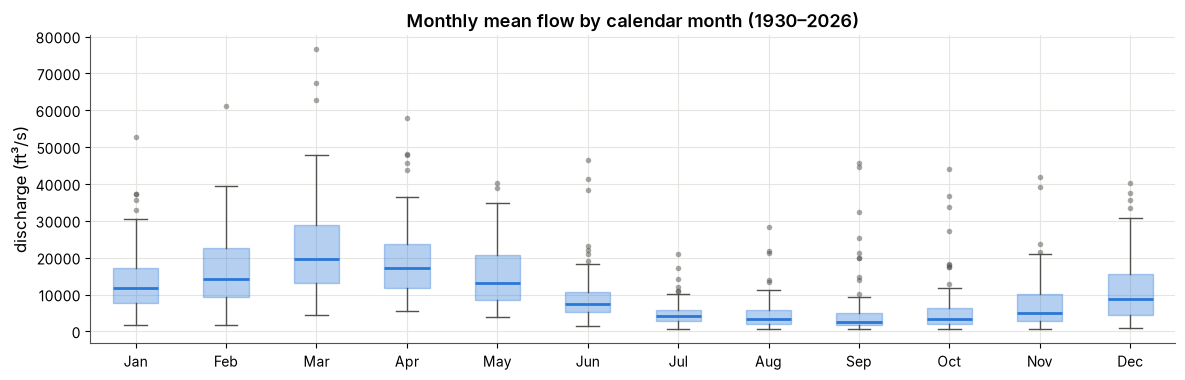

Wettest month (median): Mar (19,570 ft³/s)
Driest month (median):  Sep (2,502 ft³/s)
Ratio wettest/driest:   7.8x


In [9]:
monthly_mean = flow.resample('MS').mean()
by_month = [monthly_mean[monthly_mean.index.month == m].to_numpy() for m in range(1, 13)]
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot(
    by_month, tick_labels=month_names, widths=0.5, patch_artist=True,
    boxprops={'facecolor': BLUE, 'edgecolor': BLUE, 'alpha': 0.35},
    medianprops={'color': BLUE, 'linewidth': 2},
    whiskerprops={'color': MUTED}, capprops={'color': MUTED},
    flierprops={'marker': 'o', 'markersize': 4, 'markerfacecolor': MUTED, 'markeredgecolor': 'none', 'alpha': 0.5},
)
ax.set_title('Monthly mean flow by calendar month (1930–2026)')
ax.set_ylabel('discharge (ft³/s)')
tidy(ax)
plt.show()

medians = pd.Series([np.median(v) for v in by_month], index=month_names)
print(f"Wettest month (median): {medians.idxmax()} ({medians.max():,.0f} ft³/s)")
print(f"Driest month (median):  {medians.idxmin()} ({medians.min():,.0f} ft³/s)")
print(f"Ratio wettest/driest:   {medians.max() / medians.min():.1f}x")

**How to read it:** the line inside each box is the typical (median) flow of that month; the box holds the middle half of the years; the dots are unusual years. Flows are high in late winter and spring, when rain falls on wet soils and snow melts and the plants use little water, and low in late summer and early fall, when evaporation and plant water use are at their peak.

**Why it matters:** a series with a regular seasonal rise and fall is *not* random, because its ups and downs follow the calendar. The randomness test will reject it for that reason alone, which says nothing about whether the river has changed. That is why, later on, the seasonal cycle is removed (or the data are aggregated to annual values) before testing.

### 4. Does today's flow "remember" yesterday's?

If you know today's flow, you can make a good guess about tomorrow's: a river drains slowly, and groundwater keeps feeding it for weeks after a storm. Statisticians call this **persistence** or **autocorrelation**.

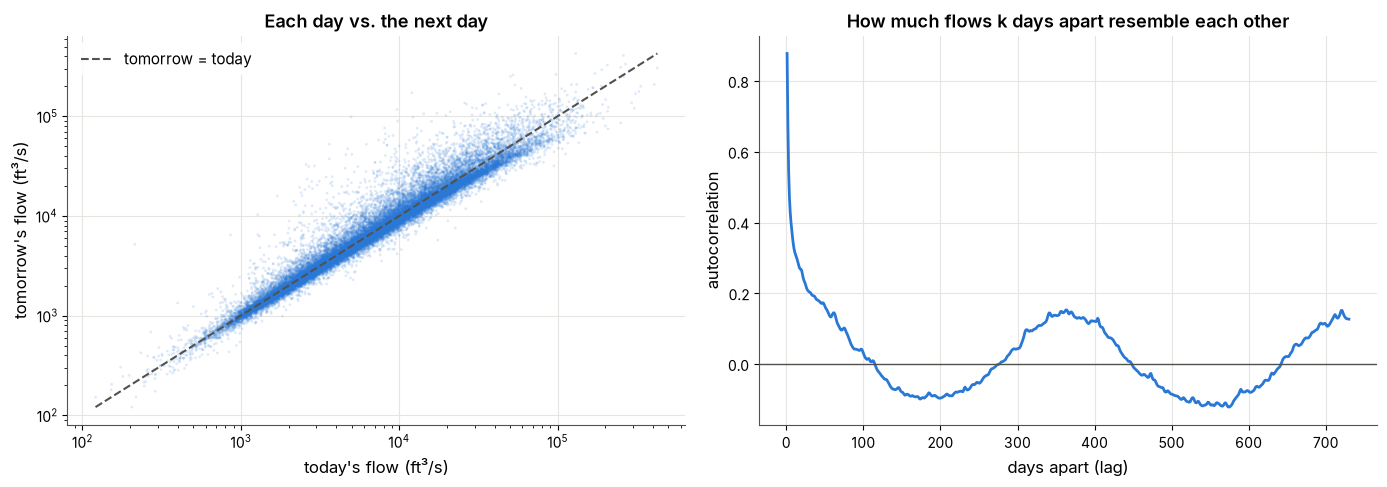

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: each dot is one day, plotted against the next day
axes[0].scatter(flow.iloc[:-1], flow.iloc[1:], s=4, color=BLUE, alpha=0.15, edgecolors='none')
lims = [flow[flow > 0].min(), flow.max()]
axes[0].plot(lims, lims, color=MUTED, linestyle='--', linewidth=1.5, label='tomorrow = today')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel("today's flow (ft³/s)")
axes[0].set_ylabel("tomorrow's flow (ft³/s)")
axes[0].set_title('Each day vs. the next day')
axes[0].legend()

# Right: how similar the series is to itself shifted by k days
lags = np.arange(1, 731)
acf = [flow.autocorr(k) for k in lags]
axes[1].plot(lags, acf, color=BLUE, linewidth=2)
axes[1].axhline(0, color=MUTED, linewidth=1)
axes[1].set_xlabel('days apart (lag)')
axes[1].set_ylabel('autocorrelation')
axes[1].set_title('How much flows k days apart resemble each other')

for ax in axes:
    tidy(ax)
plt.tight_layout()
plt.show()

**How to read it:**

* **Left:** the dots hug the dashed line, meaning tomorrow's flow is almost always close to today's. In a series without memory the dots would form a shapeless cloud.
* **Right:** autocorrelation measures how much the series resembles itself shifted by a number of days, from 1 (identical) to 0 (unrelated) to −1 (opposite). It starts near 0.9, drops quickly over the first days and then fades slowly over about three months — that is persistence. The gentle wave with peaks every 365 days is the seasonal cycle showing up again.

**Why it matters:** the independence test assumes each value tells you nothing about the next one. Daily flows break this assumption strongly, so they will fail the independence test almost regardless of the period chosen.

A common way to weaken persistence is to **aggregate** to longer time steps. The table below shows how the memory between consecutive values changes with the time step. The "monthly anomaly" is the monthly flow minus the typical flow for that calendar month, a simple way to remove the seasons.

In [11]:
monthly_anomaly = monthly_mean - monthly_mean.groupby(monthly_mean.index.month).transform('mean')
annual_mean = flow.resample('YS').mean()
complete_years = flow.resample('YS').count() >= 365
annual_complete = annual_mean[complete_years]

lag1 = pd.Series({
    'daily': flow.autocorr(1),
    'monthly': monthly_mean.autocorr(1),
    'monthly anomaly (seasons removed)': monthly_anomaly.autocorr(1),
    'annual (complete years)': annual_complete.autocorr(1),
})
n_values = pd.Series({
    'daily': len(flow),
    'monthly': len(monthly_mean),
    'monthly anomaly (seasons removed)': len(monthly_anomaly),
    'annual (complete years)': len(annual_complete),
})
# Rough threshold: below about 2/sqrt(n), the correlation is indistinguishable from chance
summary = pd.DataFrame({
    'lag-1 autocorrelation': lag1.round(2),
    'number of values': n_values,
    'chance level (±2/√n)': (2 / np.sqrt(n_values)).round(2),
})
summary

,lag-1 autocorrelation,number of values,chance level (±2/√n)
daily,0.88,35306,0.01
monthly,0.52,1160,0.06
monthly anomaly (seasons removed),0.38,1160,0.06
annual (complete years),0.08,95,0.21


**How to read it:** the closer the lag-1 autocorrelation is to 0, the weaker the memory between consecutive values. Memory is extreme for daily flows, still clear for monthly flows (partly due to the seasons), weaker but still present once the seasons are removed, and close to chance level for annual flows.

Note the last column: with many values, even a small correlation is statistically detectable. This is why the monthly anomalies can still fail the independence test even though their memory looks modest.

### 5. Are there long-term changes?

Annual averages smooth out the seasons and most of the persistence, which makes them the best scale to look for shifts and trends by eye.

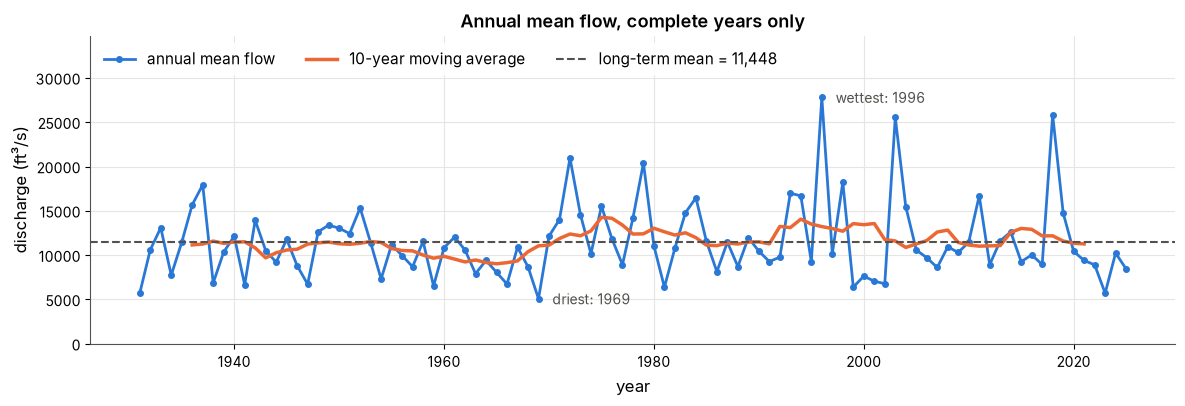

Mean of the first half (1931–1977):  10,870 ft³/s
Mean of the second half (1978–2025): 12,015 ft³/s


In [12]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(annual_complete.index.year, annual_complete, color=BLUE, linewidth=2, marker='o', markersize=4, label='annual mean flow')
rolling = annual_complete.rolling(10, center=True).mean()
ax.plot(rolling.index.year, rolling, color=ORANGE, linewidth=2.5, label='10-year moving average')
ax.axhline(annual_complete.mean(), color=MUTED, linestyle='--', linewidth=1.5, label=f'long-term mean = {annual_complete.mean():,.0f}')

for year, label in [(annual_complete.idxmax(), 'wettest'), (annual_complete.idxmin(), 'driest')]:
    ax.annotate(f'{label}: {year:%Y}', (year.year, annual_complete[year]), textcoords='offset points',
                xytext=(10, -4), color=MUTED, fontsize=10)

ax.set_ylim(0, annual_complete.max() * 1.25)  # headroom for the legend

ax.set_title('Annual mean flow, complete years only')
ax.set_xlabel('year')
ax.set_ylabel('discharge (ft³/s)')
ax.legend(loc='upper left', ncols=3)
tidy(ax)
plt.show()

first_half = annual_complete.iloc[:len(annual_complete) // 2]
second_half = annual_complete.iloc[len(annual_complete) // 2:]
print(f"Mean of the first half ({first_half.index[0]:%Y}–{first_half.index[-1]:%Y}):  {first_half.mean():,.0f} ft³/s")
print(f"Mean of the second half ({second_half.index[0]:%Y}–{second_half.index[-1]:%Y}): {second_half.mean():,.0f} ft³/s")

**How to read it:** the blue line jumps a lot from year to year (wet and dry years), while the orange 10-year moving average shows the slower behaviour: decades that were wetter or drier than the long-term mean. What matters for the homogeneity and stationarity tests is whether there is a lasting **step** (a shift to a new level) or a steady **slope** (a trend) — not ordinary wet and dry years. Judging by eye, there is a wetter stretch from the 1970s to around 2000, but flows return toward the long-term mean afterwards, without a clear step or slope. The second half of the record is about 10% wetter than the first: is that a real change or just natural variability? Answering that question is the job of the tests.

### What to expect from the RHIS tests

| What we saw | Assumption affected | Test | Expected outcome |
|---|---|---|---|
| Strong seasonal cycle (high in spring, low in late summer) | Randomness | Wallis-Moore | Rejected on daily and monthly data unless the seasons are removed |
| Strong day-to-day memory, weaker but present month to month | Independence | Wald-Wolfowitz | Rejected on daily data; possibly on monthly data, even after removing the seasons |
| No obvious step or slope in annual flows | Homogeneity, Stationarity | Mann-Whitney, Mann-Kendall | Likely not rejected on annual data |
| Skewed values with floods | — | all four | Not a problem: the tests use ranks, not raw values |

Keep this table in mind: the analysis below checks these expectations at the daily, monthly and annual scales.

## RHIS Tests

## Removing the seasonal cycle from monthly flows

As expected, the flows show seasonal variations. No visible trends are present. Some outliers are present. The first thing to do, in order to find the longest and most recent stretch that is compliant with the basic assumptions for frequency analysis (randomness, homogeneity, independence, and stationarity), is to handle the expected persistence/dependence of daily flows — usually determined by the flows from previous days — and seasonality.

In [5]:
monthly_df = target_df.resample("MS").mean().reset_index().set_index('time') # Persistence tends to disappear with aggregations to larger scales such as monthly and annual
monthly_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   flow    1160 non-null   float64
dtypes: float64(1)
memory usage: 18.1 KB


<Axes: title={'center': 'Monthly Flows — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

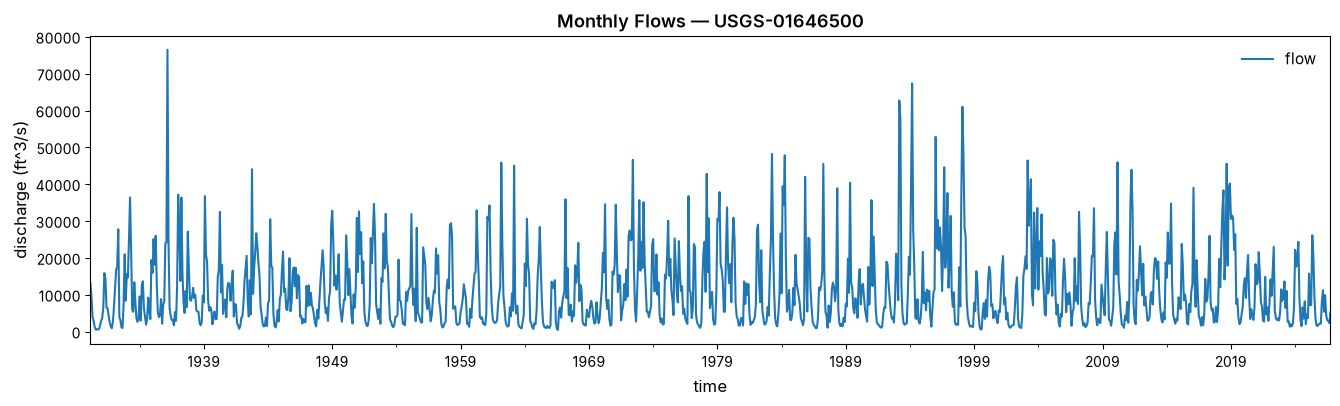

In [6]:
monthly_df.plot(
    figsize=(16, 4),
    title="Monthly Flows — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

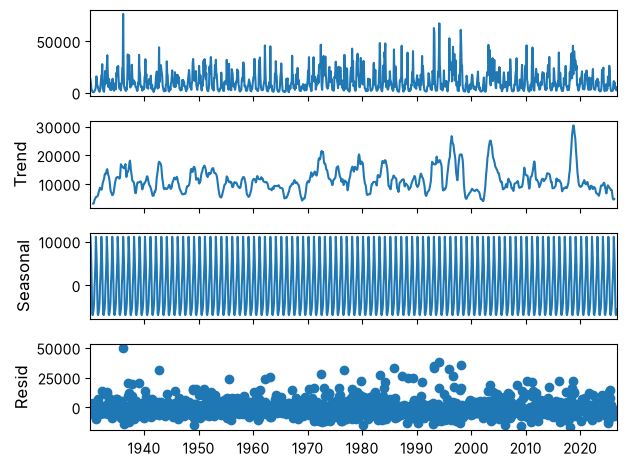

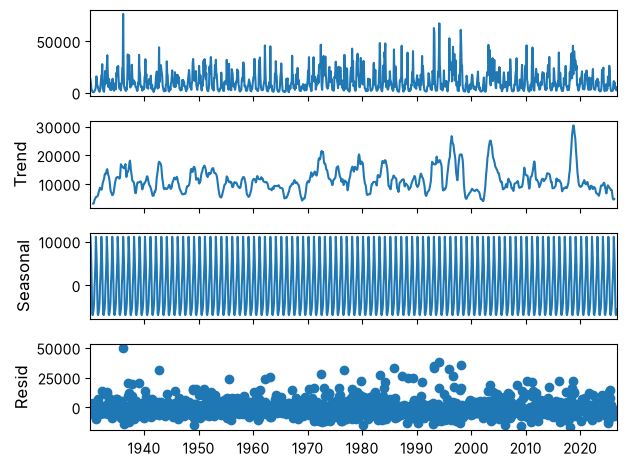

In [7]:
decomposed_ts = seasonal_decompose(monthly_df, model='additive', period=12)
decomposed_ts.plot()

In [8]:
trend_df = decomposed_ts.trend
seasonal_df = decomposed_ts.seasonal
resid_df = decomposed_ts.resid
resid_df.info()

<class 'pandas.Series'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Series name: resid
Non-Null Count  Dtype  
--------------  -----  
1148 non-null   float64
dtypes: float64(1)
memory usage: 18.1 KB


<Axes: title={'center': 'Flow residuals — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

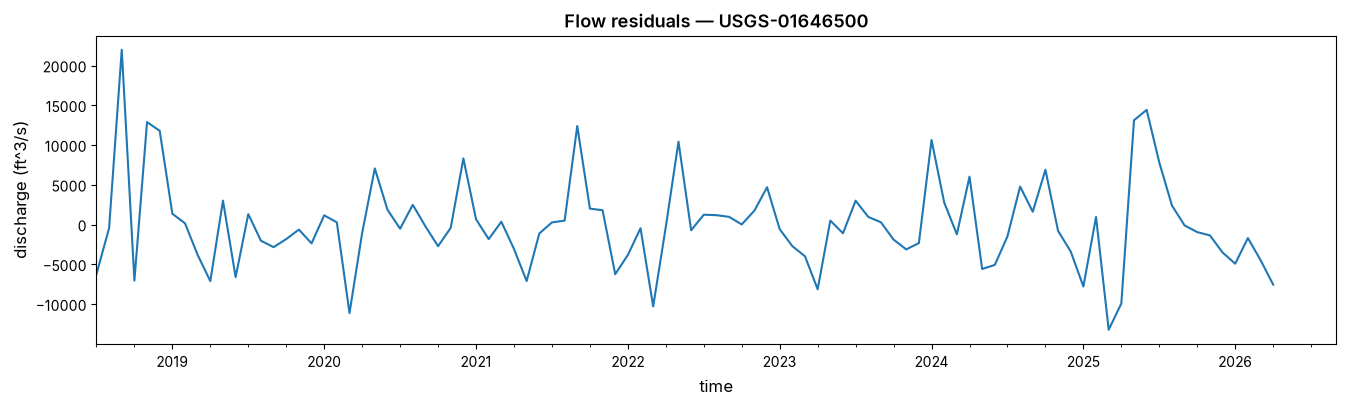

In [9]:
resid_df.iloc[-100:-1].plot(
    figsize=(16, 4),
    title="Flow residuals — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

In [10]:
rhis_resid = Rhis(resid_df.to_frame(name='Flow_resid'))
rhis_resid.numeric_orig_df.head(20)

,Flow_resid
time,
1930-03-01,NaN
1930-04-01,NaN
1930-05-01,NaN
1930-06-01,NaN
1930-07-01,NaN
1930-08-01,NaN
1930-09-01,3625.441598
1930-10-01,2877.276917
1930-11-01,743.060679


In [11]:
rhis_resid.numeric_orig_df.tail(20)

,Flow_resid
time,
2025-03-01,-13219.812364
2025-04-01,-9910.113026
2025-05-01,13123.687463
2025-06-01,14432.282808
2025-07-01,7813.364803
2025-08-01,2404.100305
2025-09-01,-103.859349
2025-10-01,-944.132184
2025-11-01,-1354.156039


In [12]:
start, end = rhis_resid.get_repr_idxs()['Flow_resid']
print(start, end)

0 0


In [13]:
p_evol_resid = rhis_resid.build_rhis_evol_dict()

In [14]:
evol_resid_df = build_rhis_evol_df(rhis_resid)
evol_resid_df.info()
evol_resid_df.head()

<class 'pandas.DataFrame'>
DatetimeIndex: 1160 entries, 1930-03-01 to 2026-10-01
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   (Flow_resid, R)         1147 non-null   float64
 1   (Flow_resid, H)         1147 non-null   float64
 2   (Flow_resid, I)         1147 non-null   float64
 3   (Flow_resid, S)         1147 non-null   float64
 4   (Flow_resid, RHIS-min)  1147 non-null   float64
dtypes: float64(5)
memory usage: 54.4 KB


series        Flow_resid                                                
hypothesis             R         H             I         S      RHIS-min
time                                                                    
1930-03-01  1.121325e-13  0.445362  8.040548e-08  0.929553  1.121325e-13
1930-04-01  1.121325e-13  0.445362  8.040548e-08  0.929553  1.121325e-13
1930-05-01  1.121325e-13  0.445362  8.040548e-08  0.929553  1.121325e-13
1930-06-01  1.121325e-13  0.445362  8.040548e-08  0.929553  1.121325e-13
1930-07-01  1.121325e-13  0.445362  8.040548e-08  0.929553  1.121325e-13

In [15]:
evol_resid_df.tail(20)

series     Flow_resid                                        
hypothesis          R         H         I         S  RHIS-min
time                                                         
2025-03-01   0.000682  0.201336  0.004742  0.079802  0.000682
2025-04-01   0.002121  0.038319  0.013622  0.006044  0.002121
2025-05-01   0.006438  0.005075  0.023531  0.000093  0.000093
2025-06-01   0.001749  0.008113  0.074246  0.000186  0.000186
2025-07-01   0.005729  0.012186  0.134056  0.000677  0.000677
2025-08-01   0.018321  0.037336  0.246545  0.002499  0.002499
2025-09-01   0.056530  0.060602  0.460995  0.009375  0.009375
2025-10-01        NaN       NaN       NaN       NaN       NaN
2025-11-01        NaN       NaN       NaN       NaN       NaN
2025-12-01        NaN       NaN       NaN       NaN       NaN
2026-01-01        NaN       NaN       NaN       NaN       NaN
2026-02-01        NaN       NaN       NaN       NaN       NaN
2026-03-01        NaN       NaN       NaN       NaN       NaN
2026-04-01        NaN       NaN       NaN       NaN       NaN
2026-05-01        NaN       NaN       NaN       NaN       NaN
2026-06-01        NaN       NaN       NaN       NaN       NaN
2026-07-01        NaN       NaN       NaN       NaN       NaN
2026-08-01        NaN       NaN       NaN       NaN       NaN
2026-09-01        NaN       NaN       NaN       NaN       NaN
2026-10-01        NaN       NaN       NaN       NaN       NaN

In [16]:
repr_resid_df = build_repr_df(rhis_resid)

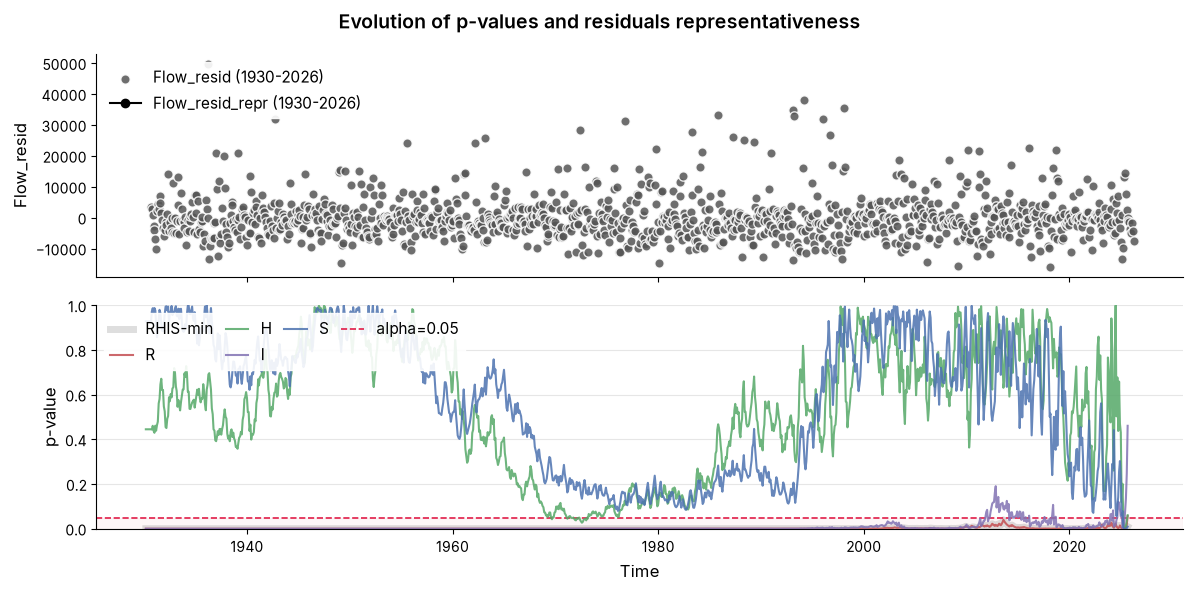

In [17]:
plot_rhis_evolution(
    rhis_resid.numeric_orig_df,
    evol_resid_df, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='Evolution of p-values and residuals representativeness',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

## RHIS-compliant series from daily flows

In daily frequency, we can expect to have high persistence/dependence even in short slices of the series. So, the RHIS-compliant stretch should be a very short series due to rejection of independence hypothesis, or even there are no RHIS-compliant series, if the last test which is performed with the 8 most recent measurements rejects any of the hypothesis. This should take a little while given the size of the series. 

In [10]:
rhis = Rhis(target_df)
repr_idxs = rhis.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values

print(repr_idxs)

{'value': (0, 0)}


The method returned (0, 0), which means that there is no RHIS compliant stretch for this series.

## Let's look at the p-value evolutions

In [11]:
p_evol = rhis.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df = build_rhis_evol_df(rhis) # Helper function to create a datafarme from the p-value evolutions
repr_df = build_repr_df(rhis) # Helper function to create a datafarme with the RHIS-compliant stretch, which is None in this case

In [14]:
start, stop = repr_idxs["value"]
print(start, stop)
# repr_df.iloc[start:stop].plot(
#     kind="line", figsize=(8, 4),
#     style="o",
#     linestyle="None",
#     title="RHIS-compliant Daily streamflow — USGS-01646500",
#     xlabel="time", ylabel="discharge (ft^3/s)",
# )

0 0


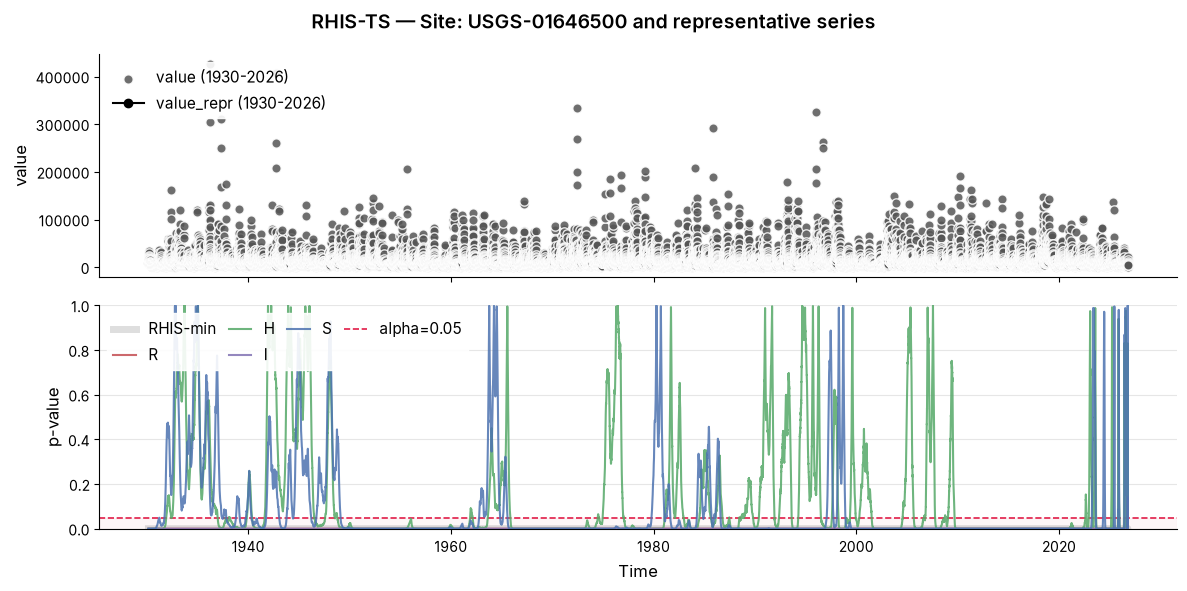

In [35]:
plot_rhis_evolution(
    rhis.numeric_orig_df,
    rhis_df, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

The p-values start all below alpha level. Going towards the most recent, homogeneity and stationarity move above and below the rejection level many times, but randomness and independence continue being rejected until the last test, with the most recent minimum stretch (8 values).

## Looking closer (last 100 elements)

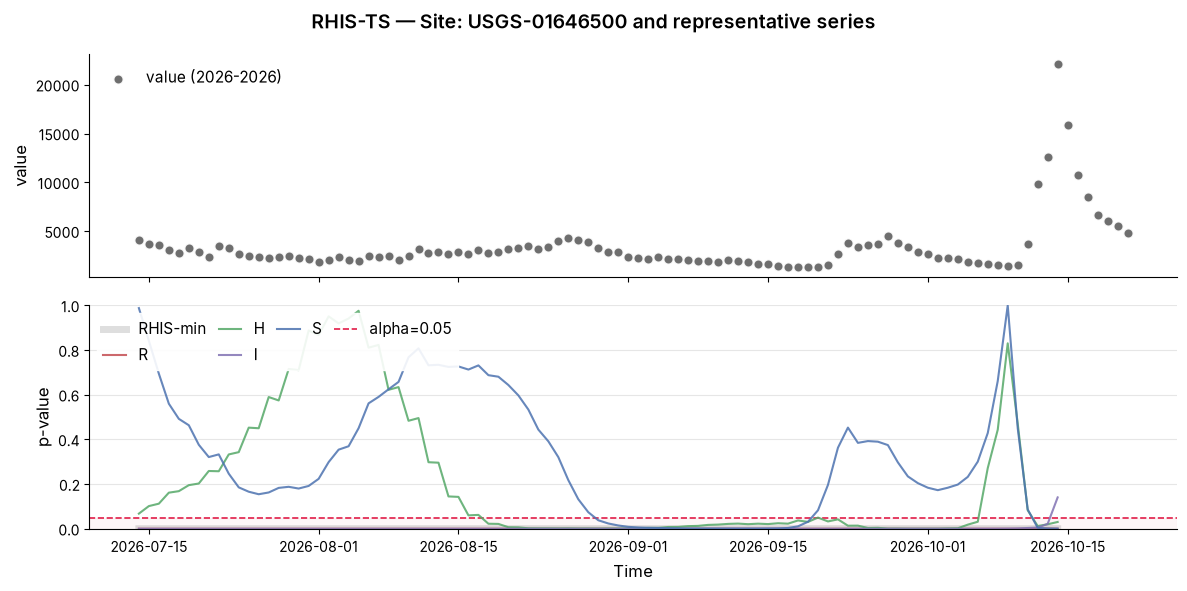

In [32]:
plot_rhis_evolution(
    rhis.numeric_orig_df.iloc[len(df) - 100:],
    rhis_df.iloc[len(df) - 100:], 0.05,
    show_repr=False,
    save=False,
    repr_df=None,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

Here we can see that randomness and independence keep being rejected until the last test with 8 most recent values, as well as homogeneity and stationarity. That's why rhis_ts resulted in no RHIS-compliant stretch.

# What about monthly scale?

We can expect less dependence between flows, but seasonality will still be present and should continue to cause several rejections of randomness and independence.

In [33]:
df_monthly = target_df.resample("MS").mean().reset_index().set_index('time')

<Axes: title={'center': 'Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

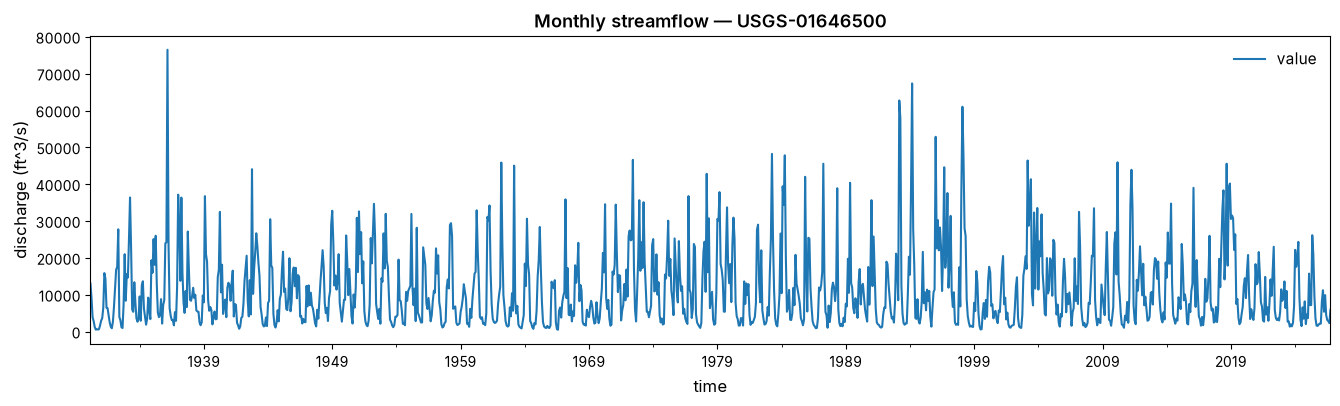

In [36]:
df_monthly.plot(
    figsize=(16, 4),
    title="Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

{'value': (1147, 1160)}


<Axes: title={'center': 'RHIS-compliant Monthly streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

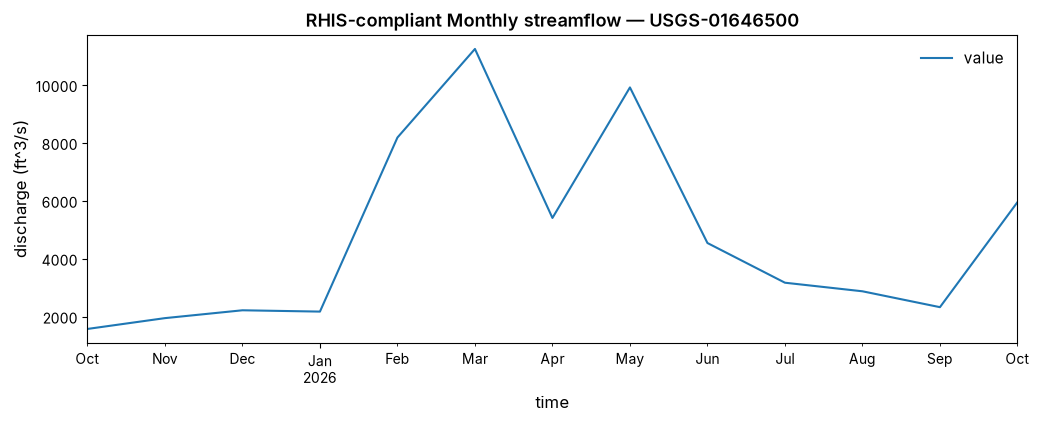

In [ ]:
rhis_m = Rhis(df_monthly)
repr_idxs_m = rhis_m.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_m)

p_evol = rhis_m.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_m = build_rhis_evol_df(rhis_m) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_m = build_repr_df(rhis_m) # This is just a helper function to create a datafarme from with the representative stretches from each time series

start, stop = repr_idxs_m["value"]
repr_df_m.iloc[start:stop].plot(
    figsize=(12, 4),
    title="RHIS-compliant Monthly streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

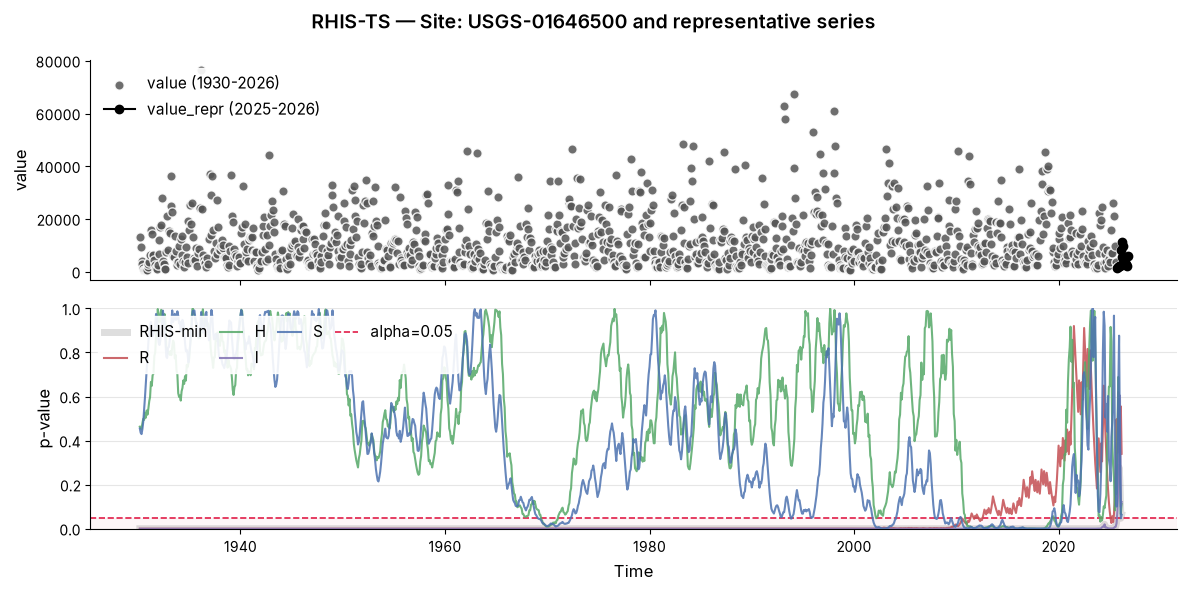

In [40]:
plot_rhis_evolution(
    rhis_m.numeric_orig_df,
    rhis_df_m, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_m,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

Seasonality still has significant impact on dependence on the monthly scale. So, analyzing the series without any pre-treatment regarding seasons returns a very short RHIS-compliant series. Be careful here, we cannot say this stretch is representative, only that it does not provide enough evidence to reject the RHIS hypotheses, and looking at the full series we can see clearly that there is cyclic variations (seasonality). The right thing to do is separate the data into seasons.

## And annual flows?

In annual scale, we can see that the entire time series is RHIS-compliant, which means that the series doesn't provide enough evidence for the detection of any variability pattern.

### Rescale to annual frequency

<Axes: title={'center': 'Annual streamflow — USGS-01646500'}, xlabel='time', ylabel='discharge (ft^3/s)'>

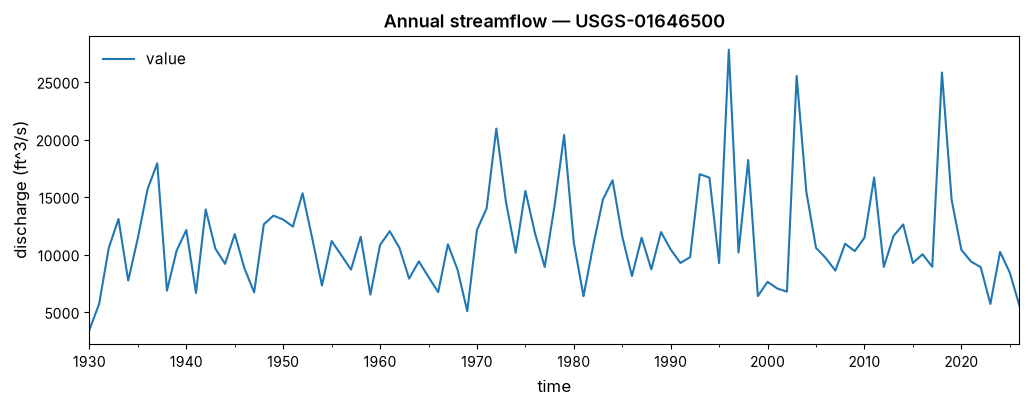

In [42]:
df_annual = target_df.resample("YS").mean().reset_index().set_index('time')

df_annual.plot(
    figsize=(12, 4),
    title="Annual streamflow — USGS-01646500",
    xlabel="time", ylabel="discharge (ft^3/s)",
)

### Get representative indexes and build p-value evolutions

In [43]:
rhis_y = Rhis(df_annual)
repr_idxs_y = rhis_y.get_repr_idxs() # Get the indexes that define the most recent RHIS-compliant stretch. It doesn't save the p-values
print(repr_idxs_y)

p_evol = rhis_y.build_rhis_evol_dict() # Save the p-value evolutions
rhis_df_y = build_rhis_evol_df(rhis_y) # This is just a helper function to create a datafarme from the p-value evolutions
repr_df_y = build_repr_df(rhis_y) # This is just a helper function to create a datafarme from with the representative stretches from each time series

{'value': (0, 97)}


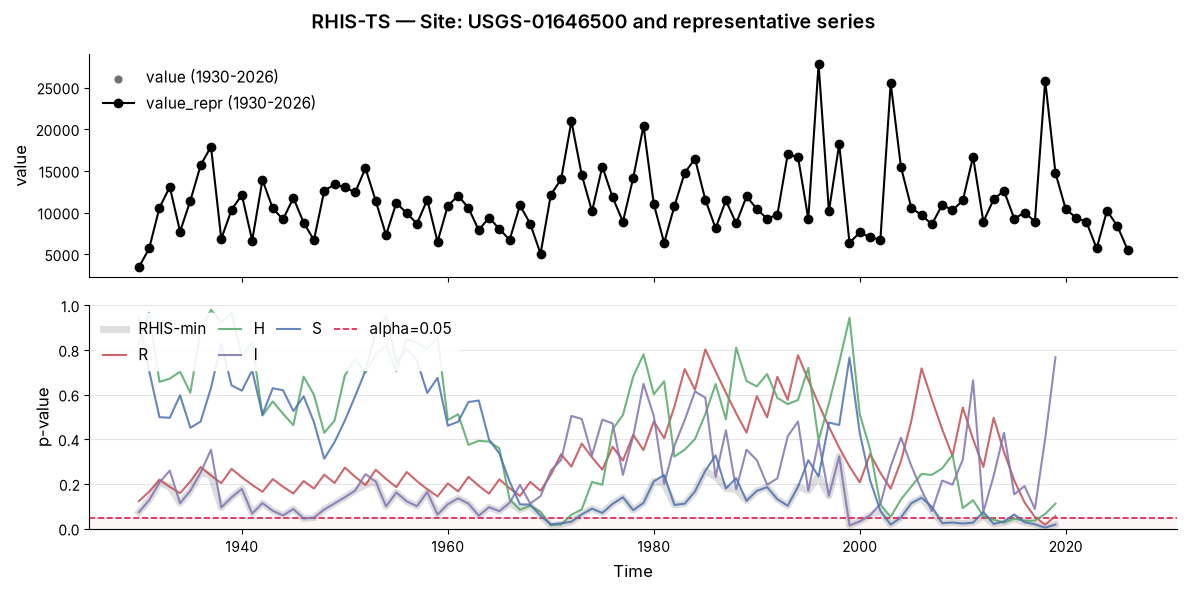

In [44]:
plot_rhis_evolution(
    rhis_y.numeric_orig_df,
    rhis_df_y, 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_df_y,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

## Let's decompose the series into trend, seasonal, and random components

In [ ]:
resid = result.resid
resid.info()
rhis_resid = Rhis(resid.to_frame(name='value_residual'))
start, end = rhis_resid.get_repr_idxs()['value_residual']
p_evol_resid = rhis_resid.build_rhis_evol_dict()
rhis_resid_df = build_rhis_evol_df(rhis_resid)
repr_resid_df = build_repr_df(rhis_resid)
plot_rhis_evolution(
    rhis_resid.numeric_orig_df.iloc[len(df) - 500:],
    rhis_resid_df.iloc[len(df) - 500:], 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )

<class 'pandas.Series'>
DatetimeIndex: 35299 entries, 1930-03-01 to 2026-10-21
Series name: resid
Non-Null Count  Dtype  
--------------  -----  
34935 non-null  float64
dtypes: float64(1)
memory usage: 551.5 KB


In [59]:
print(start, end)

35107 35299


In [61]:
rhis_resid.numeric_orig_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 35299 entries, 1930-03-01 to 2026-10-21
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   value_residual  34935 non-null  float64
dtypes: float64(1)
memory usage: 551.5 KB


In [56]:
p_evol_resid = rhis_resid.build_rhis_evol_dict()
rhis_resid_df = build_rhis_evol_df(rhis_resid)
repr_resid_df = build_repr_df(rhis_resid)


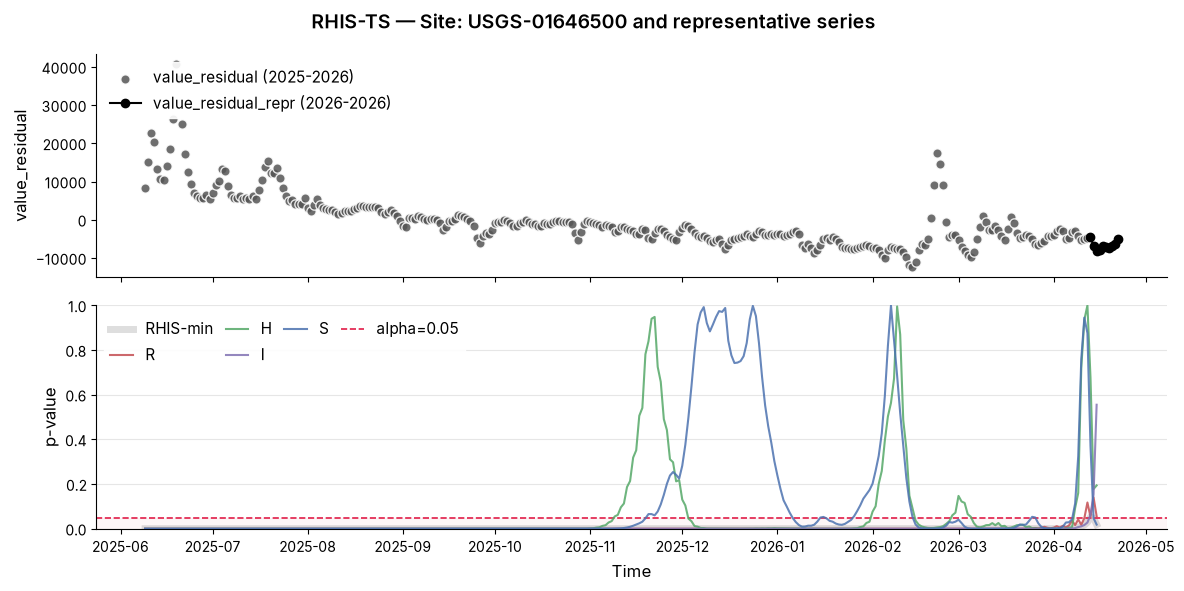

In [60]:
plot_rhis_evolution(
    rhis_resid.numeric_orig_df.iloc[len(df) - 500:],
    rhis_resid_df.iloc[len(df) - 500:], 0.05,
    show_repr=True,
    save=False,
    repr_df=repr_resid_df,
    figtitle='RHIS-TS — Site: USGS-01646500 and representative series',
    savename='USGS-01646500',
    figsize=(12, 6)
    )